In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/blueberrye-io/diode-iv-measurements/main/data/1n4004_forward.csv"

df = pd.read_csv(url)

# Inspect the data
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nColumn information:")
print(df.info())

print("\nMissing values:")
print(df.isna().sum())

print("\nSummary statistics:")
print(df.describe())


Dataset shape: (171, 3)

First five rows:
   v_set    v_meas        i_meas
0  0.000       NaN           NaN
1  0.005  0.000000  0.000000e+00
2  0.010 -0.000242 -1.595252e-05
3  0.015  0.003574  5.137439e-08
4  0.020  0.009415  5.388046e-08

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171 entries, 0 to 170
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   v_set   171 non-null    float64
 1   v_meas  170 non-null    float64
 2   i_meas  170 non-null    float64
dtypes: float64(3)
memory usage: 4.1 KB
None

Missing values:
v_set     0
v_meas    1
i_meas    1
dtype: int64

Summary statistics:
            v_set      v_meas        i_meas
count  171.000000  170.000000  1.700000e+02
mean     0.425000    0.415809  5.463590e-03
std      0.247538    0.245168  1.252564e-02
min      0.000000   -0.000242 -1.595252e-05
25%      0.212500    0.205774  1.133996e-07
50%      0.425000    0.415521  1.882620e-05
75%      0

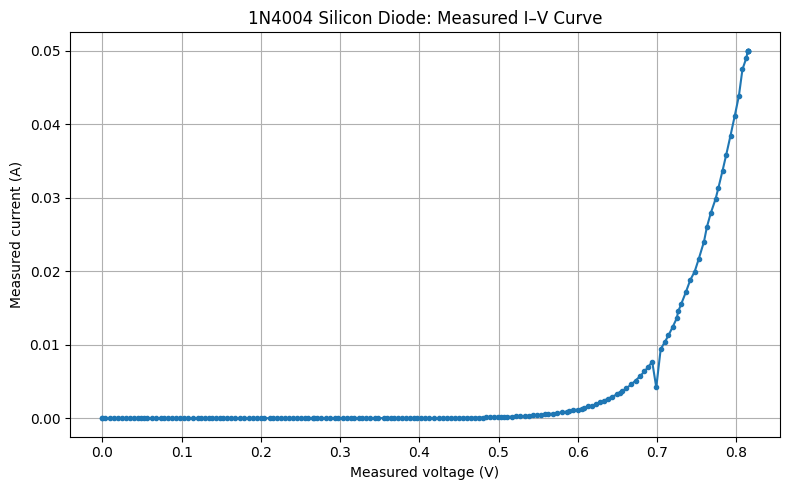

In [ ]:

# Keep rows with valid measured voltage and current
valid = df.dropna(subset=["v_meas", "i_meas"]).copy()

# Plot the measured current against measured voltage
plt.figure(figsize=(8, 5))
plt.plot(valid["v_meas"], valid["i_meas"], "o-", markersize=3)

plt.xlabel("Measured voltage (V)")
plt.ylabel("Measured current (A)")
plt.title("1N4004 Silicon Diode: Measured I–V Curve")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Show measurements around the suspicious region
print(
    df.loc[
        df["v_set"].between(0.68, 0.74),
        ["v_set", "v_meas", "i_meas"]
    ].to_string(index=False)
)

# Show negative or zero measured currents
print("\nNegative or zero currents:")
print(
    df.loc[
        df["i_meas"] <= 0,
        ["v_set", "v_meas", "i_meas"]
    ].to_string(index=False)
)



 v_set   v_meas   i_meas
 0.680 0.667478 0.004593
 0.685 0.673072 0.005125
 0.690 0.678652 0.005715
 0.695 0.684280 0.006372
 0.700 0.689282 0.007017
 0.705 0.694059 0.007690
 0.710 0.699173 0.004208
 0.715 0.704784 0.009417
 0.720 0.709729 0.010321
 0.725 0.714566 0.011276
 0.730 0.719855 0.012408
 0.735 0.724997 0.013598
 0.740 0.726870 0.014535

Negative or zero currents:
 v_set    v_meas    i_meas
 0.005  0.000000  0.000000
 0.010 -0.000242 -0.000016


Original rows: 171
Rows available for modelling: 169
Rows excluded: 2


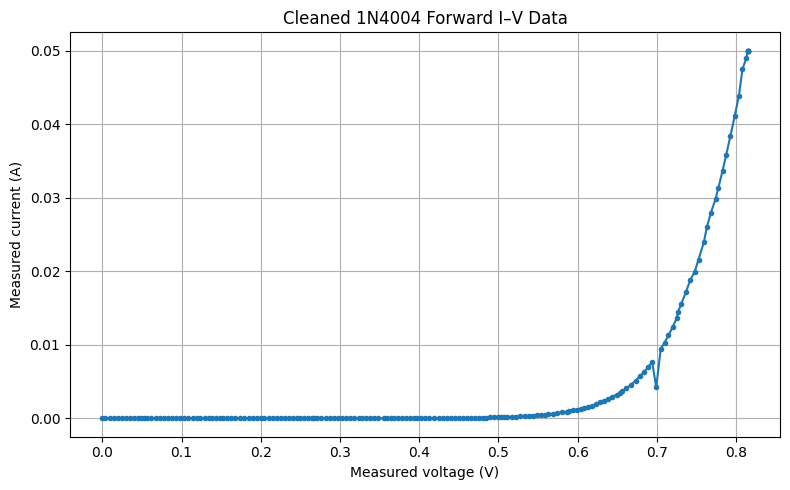

In [ ]:

# Keep the original dataframe unchanged
clean_df = df.dropna(subset=["v_meas", "i_meas"]).copy()

# For the initial forward-current experiment, retain
# nonnegative measured voltage and current.
# Keep the suspicious 0.71 V point for now.
clean_df = clean_df[
    (clean_df["v_meas"] >= 0) &
    (clean_df["i_meas"] >= 0)
].copy()

clean_df = clean_df.sort_values("v_meas")

print("Original rows:", len(df))
print("Rows available for modelling:", len(clean_df))
print("Rows excluded:", len(df) - len(clean_df))

plt.figure(figsize=(8, 5))
plt.plot(clean_df["v_meas"], clean_df["i_meas"], "o-", markersize=3)
plt.xlabel("Measured voltage (V)")
plt.ylabel("Measured current (A)")
plt.title("Cleaned 1N4004 Forward I–V Data")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Sort by measured voltage
data_ml = clean_df.sort_values("v_meas").reset_index(drop=True)

X = data_ml[["v_meas"]]
y = data_ml["i_meas"]

# Sequential split: 60% train, 20% validation, 20% test
n = len(data_ml)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

# Define the models
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        random_state=42
    )
}

# Fit using training data only
for model in models.values():
    model.fit(X_train, y_train)

# Compare models on validation data
results = []

for name, model in models.items():
    pred = model.predict(X_val)
    results.append({
        "Model": name,
        "Validation MAE (A)": mean_absolute_error(y_val, pred),
        "Validation RMSE (A)": np.sqrt(mean_squared_error(y_val, pred)),
        "Validation R²": r2_score(y_val, pred)
    })

results_df = pd.DataFrame(results)
print("\nValidation results:")
print(results_df.round(6).to_string(index=False))


Training rows: 101
Validation rows: 34
Test rows: 34

Validation results:
            Model  Validation MAE (A)  Validation RMSE (A)  Validation R²
    Mean baseline            0.001391             0.001871      -1.235022
Linear regression            0.001348             0.001835      -1.150131
    Random forest            0.001265             0.001780      -1.021605


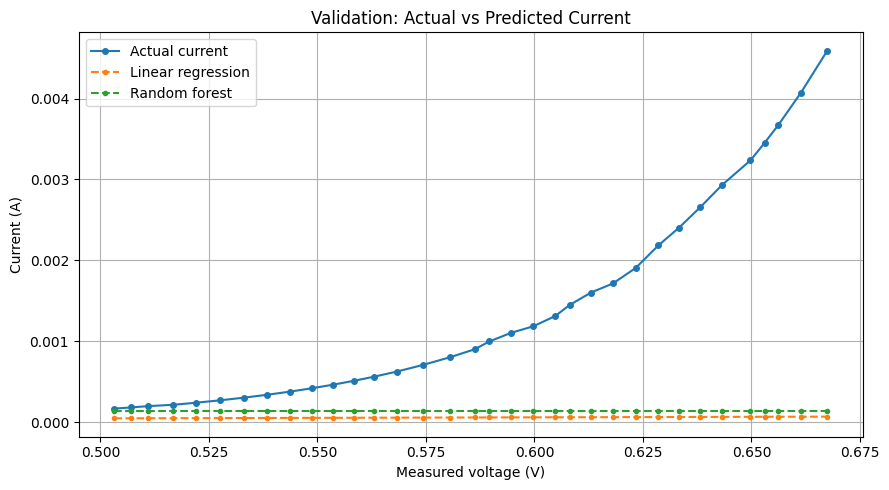

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    X_val["v_meas"], y_val,
    "o-", label="Actual current", markersize=4
)

for name in ["Linear regression", "Random forest"]:
    predictions = models[name].predict(X_val)
    plt.plot(
        X_val["v_meas"], predictions,
        "o--", label=name, markersize=3
    )

plt.xlabel("Measured voltage (V)")
plt.ylabel("Current (A)")
plt.title("Validation: Actual vs Predicted Current")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#Blue line — Actual current: The measured diode current rises as voltage increases.
#Orange line — Linear regression: Its predictions remain close to the bottom of the graph and do not capture the sharp increase in current.
#Green line — Random forest: Its predictions are also nearly flat and substantially underestimate the actual current at higher voltages.


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []

for name, model in model.items():
    y_pred = model.predict(X_val)

    results.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_val, y_pred),
        "RMSE (A)": np.sqrt(mean_squared_error(y_val, y_pred)),
        "R²": r2_score(y_val, y_pred)
    })

results_df = pd.DataFrame(results)
print(results_df)


AttributeError: 'RandomForestRegressor' object has no attribute 'items'

In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Random forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)

print("Both models are trained.")


In [ ]:

#Check that your cleaned dataset and split labels exist
print(data.columns)
print(data.shape)


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/blueberrye-io/diode-iv-measurements/main/data/1n4004_forward.csv"

data = pd.read_csv(url)

print("Dataset shape:", data.shape)
print(data.head())


Dataset shape: (171, 3)
   v_set    v_meas        i_meas
0  0.000       NaN           NaN
1  0.005  0.000000  0.000000e+00
2  0.010 -0.000242 -1.595252e-05
3  0.015  0.003574  5.137439e-08
4  0.020  0.009415  5.388046e-08


In [ ]:

print("Dataset information:")
data.info()

print("\nMissing values:")
print(data.isnull().sum())

print("\nStatistical summary:")
print(data.describe())

print("\nRows with missing values:")
print(data[data.isnull().any(axis=1)])


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171 entries, 0 to 170
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   v_set   171 non-null    float64
 1   v_meas  170 non-null    float64
 2   i_meas  170 non-null    float64
dtypes: float64(3)
memory usage: 4.1 KB

Missing values:
v_set     0
v_meas    1
i_meas    1
dtype: int64

Statistical summary:
            v_set      v_meas        i_meas
count  171.000000  170.000000  1.700000e+02
mean     0.425000    0.415809  5.463590e-03
std      0.247538    0.245168  1.252564e-02
min      0.000000   -0.000242 -1.595252e-05
25%      0.212500    0.205774  1.133996e-07
50%      0.425000    0.415521  1.882620e-05
75%      0.637500    0.627259  2.114819e-03
max      0.850000    0.814668  5.003511e-02

Rows with missing values:
   v_set  v_meas  i_meas
0    0.0     NaN     NaN


Cleaned dataset shape: (170, 2)
     v_meas        i_meas
0 -0.000242 -1.595252e-05
1  0.000000  0.000000e+00
2  0.003574  5.137439e-08
3  0.009415  5.388046e-08
4  0.014409  4.886832e-08


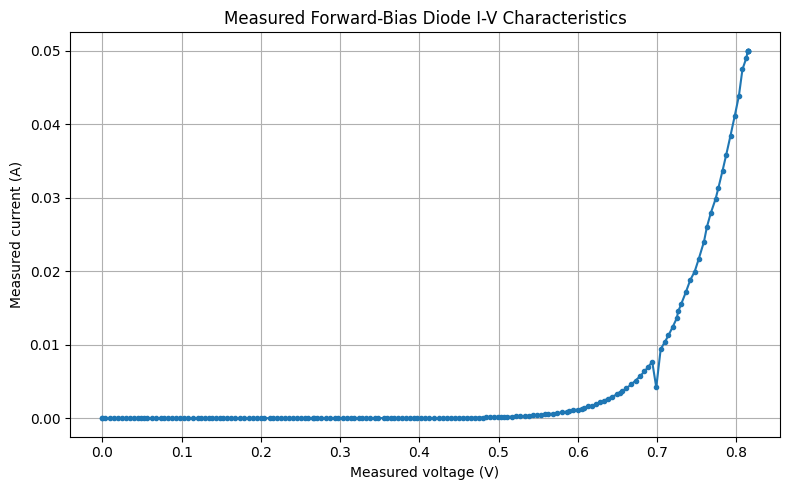

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Remove rows where measured voltage or current is missing
data = data.dropna(subset=["v_meas", "i_meas"]).copy()

# Keep the columns needed for our prediction task
data = data[["v_meas", "i_meas"]].copy()

# Sort measurements by voltage for plotting and splitting
data = data.sort_values("v_meas").reset_index(drop=True)

print("Cleaned dataset shape:", data.shape)
print(data.head())

# Plot the measured diode I-V curve
plt.figure(figsize=(8, 5))
plt.plot(data["v_meas"], data["i_meas"], "o-", markersize=3)
plt.xlabel("Measured voltage (V)")
plt.ylabel("Measured current (A)")
plt.title("Measured Forward-Bias Diode I-V Characteristics")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Use lower voltages for training, middle voltages for validation,
# and highest voltages for final testing.
X = data[["v_meas"]]
y = data["i_meas"]

n = len(data)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("Training voltage range:",
      X_train["v_meas"].min(), "to", X_train["v_meas"].max())
print("Validation voltage range:",
      X_val["v_meas"].min(), "to", X_val["v_meas"].max())
print("Test voltage range:",
      X_test["v_meas"].min(), "to", X_test["v_meas"].max())

# Define models
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

# Train each model using training data only
for model in models.values():
    model.fit(X_train, y_train)

print("\nModels trained successfully.")



Training voltage range: -0.0002423983 to 0.49931
Validation voltage range: 0.503231 to 0.6674781
Test voltage range: 0.6730717 to 0.8146680333333333

Models trained successfully.


            Model  MAE (A)  RMSE (A)        R2
    Random forest 0.001267  0.001781 -1.024895
Linear regression 0.001348  0.001835 -1.150312
    Mean baseline 0.001391  0.001872 -1.235523


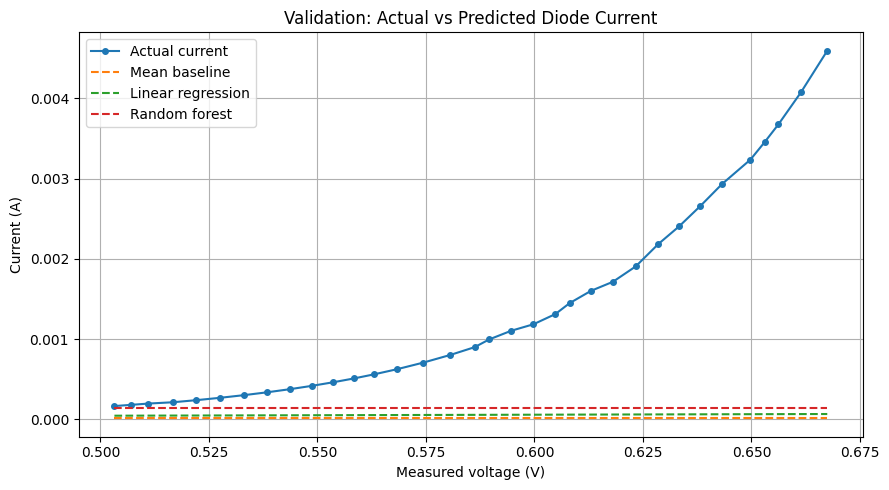

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

results = []

for name, model in models.items():
    y_pred = model.predict(X_val)

    results.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_val, y_pred),
        "RMSE (A)": np.sqrt(mean_squared_error(y_val, y_pred)),
        "R2": r2_score(y_val, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE (A)")
print(results_df.to_string(index=False))

# Plot validation predictions against actual measurements
plt.figure(figsize=(9, 5))
plt.plot(X_val["v_meas"], y_val, "o-", label="Actual current", markersize=4)

for name, model in models.items():
    plt.plot(
        X_val["v_meas"],
        model.predict(X_val),
        "--",
        label=name
    )

plt.xlabel("Measured voltage (V)")
plt.ylabel("Current (A)")
plt.title("Validation: Actual vs Predicted Diode Current")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split

# First, set aside 20% for the final test set
X_trainval, X_test_random, y_trainval, y_test_random = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Split the remaining data into training and validation sets
X_train_random, X_val_random, y_train_random, y_val_random = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42
)

# Train fresh models so the earlier experiment stays unchanged
random_models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

for model in random_models.values():
    model.fit(X_train_random, y_train_random)

print("Training rows:", len(X_train_random))
print("Validation rows:", len(X_val_random))
print("Test rows:", len(X_test_random))
print("Random-split models trained.")


Training rows: 102
Validation rows: 34
Test rows: 34
Random-split models trained.


            Model  MAE (A)  RMSE (A)        R2
    Random forest 0.000169  0.000467  0.997671
Linear regression 0.006761  0.008616  0.208518
    Mean baseline 0.007229  0.010071 -0.081233


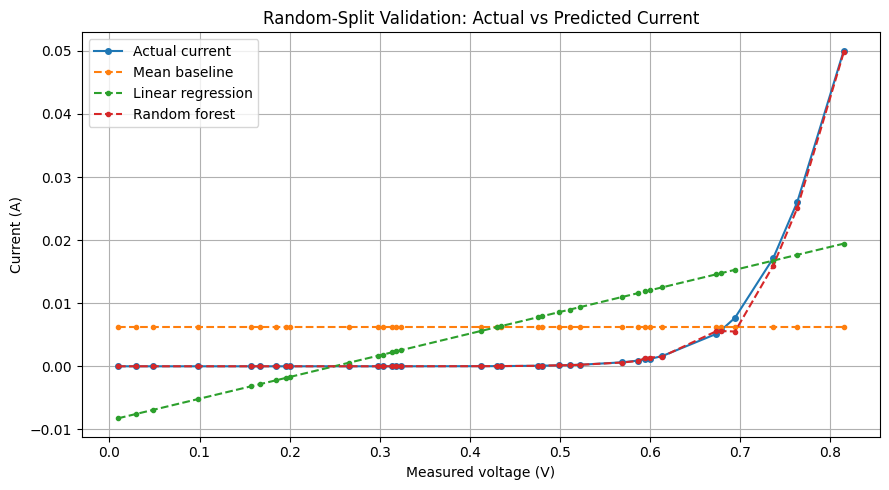

In [ ]:

results_random = []

for name, model in random_models.items():
    y_pred = model.predict(X_val_random)

    results_random.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_val_random, y_pred),
        "RMSE (A)": np.sqrt(mean_squared_error(y_val_random, y_pred)),
        "R2": r2_score(y_val_random, y_pred)
    })

results_random_df = pd.DataFrame(results_random).sort_values("RMSE (A)")
print(results_random_df.to_string(index=False))

# Plot actual and predicted validation currents
order = np.argsort(X_val_random["v_meas"].to_numpy())
X_plot = X_val_random.iloc[order]
y_plot = y_val_random.iloc[order]

plt.figure(figsize=(9, 5))
plt.plot(X_plot["v_meas"], y_plot, "o-", label="Actual current", markersize=4)

for name, model in random_models.items():
    plt.plot(
        X_plot["v_meas"],
        model.predict(X_plot),
        "o--",
        label=name,
        markersize=3
    )

plt.xlabel("Measured voltage (V)")
plt.ylabel("Current (A)")
plt.title("Random-Split Validation: Actual vs Predicted Current")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

test_results = []

for name, model in random_models.items():
    y_pred = model.predict(X_test_random)

    test_results.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_test_random, y_pred),
        "RMSE (A)": np.sqrt(mean_squared_error(y_test_random, y_pred)),
        "R2": r2_score(y_test_random, y_pred)
    })

test_results_df = pd.DataFrame(test_results).sort_values("RMSE (A)")
print(test_results_df.to_string(index=False))


            Model  MAE (A)  RMSE (A)        R2
    Random forest 0.000171  0.000422  0.998905
Linear regression 0.006944  0.009559  0.439677
    Mean baseline 0.008777  0.012815 -0.007052


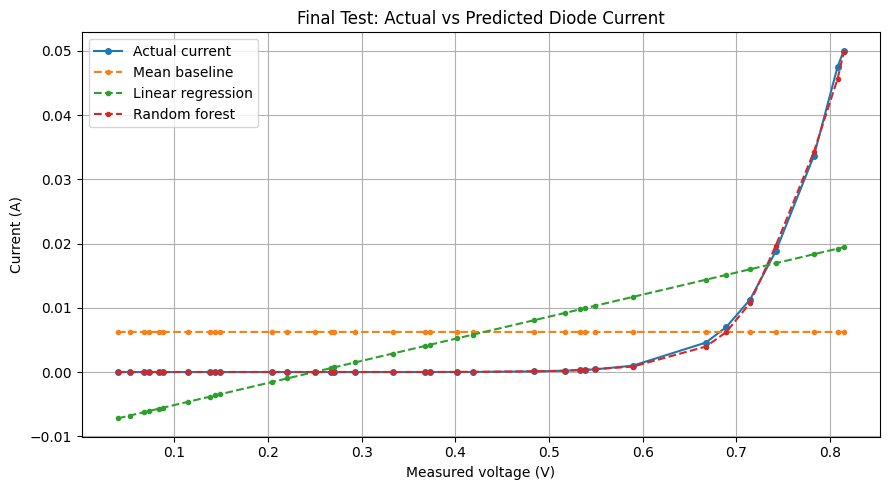

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Sort test samples by voltage so the plot is easy to read
order = np.argsort(X_test_random["v_meas"].to_numpy())
X_test_plot = X_test_random.iloc[order]
y_test_plot = y_test_random.iloc[order]

plt.figure(figsize=(9, 5))

plt.plot(
    X_test_plot["v_meas"], y_test_plot,
    "o-", label="Actual current", markersize=4
)

for name, model in random_models.items():
    plt.plot(
        X_test_plot["v_meas"],
        model.predict(X_test_plot),
        "o--", label=name, markersize=3
    )

plt.xlabel("Measured voltage (V)")
plt.ylabel("Current (A)")
plt.title("Final Test: Actual vs Predicted Diode Current")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Results from the voltage-ordered validation experiment
ordered_results = pd.DataFrame([
    {"Split": "Voltage-ordered validation",
     "Model": row["Model"],
     "MAE (A)": row["MAE (A)"],
     "RMSE (A)": row["RMSE (A)"],
     "R2": row["R2"]}
    for _, row in results_df.iterrows()
])

# Results from the random-split final test experiment
random_test_results = pd.DataFrame([
    {"Split": "Random-split test",
     "Model": row["Model"],
     "MAE (A)": row["MAE (A)"],
     "RMSE (A)": row["RMSE (A)"],
     "R2": row["R2"]}
    for _, row in test_results_df.iterrows()
])

comparison = pd.concat(
    [ordered_results, random_test_results],
    ignore_index=True
)

print(comparison.to_string(index=False))


                     Split             Model  MAE (A)  RMSE (A)        R2
Voltage-ordered validation     Random forest 0.001267  0.001781 -1.024895
Voltage-ordered validation Linear regression 0.001348  0.001835 -1.150312
Voltage-ordered validation     Mean baseline 0.001391  0.001872 -1.235523
         Random-split test     Random forest 0.000171  0.000422  0.998905
         Random-split test Linear regression 0.006944  0.009559  0.439677
         Random-split test     Mean baseline 0.008777  0.012815 -0.007052


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Create SVR pipeline: scale voltage, then fit SVR
svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.001)
)

# Train on the existing random training set
svr_model.fit(X_train_random, y_train_random)

# Evaluate on validation data only
y_pred_svr = svr_model.predict(X_val_random)

print("SVR validation results")
print("MAE (A):", mean_absolute_error(y_val_random, y_pred_svr))
print("RMSE (A):", np.sqrt(mean_squared_error(y_val_random, y_pred_svr)))
print("R2:", r2_score(y_val_random, y_pred_svr))


SVR validation results
MAE (A): 0.0005903259944978407
RMSE (A): 0.0007039967611110583
R2: 0.9947162863030995


In [ ]:

y_pred_svr_test = svr_model.predict(X_test_random)

print("SVR test results")
print("MAE (A):", mean_absolute_error(y_test_random, y_pred_svr_test))
print("RMSE (A):", np.sqrt(mean_squared_error(y_test_random, y_pred_svr_test)))
print("R2:", r2_score(y_test_random, y_pred_svr_test))


SVR test results
MAE (A): 0.000851703981759185
RMSE (A): 0.0009209346591025968
R2: 0.9947993015867678


In [ ]:

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

svr_pipeline = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)

param_grid = {
    "svr__C": [1, 10, 100, 1000],
    "svr__epsilon": [0.0001, 0.001, 0.005],
    "svr__gamma": ["scale", 0.1, 1]
}

grid = GridSearchCV(
    svr_pipeline,
    param_grid,
    scoring="neg_mean_absolute_error",
    cv=3
)

grid.fit(X_train_random, y_train_random)

print("Best parameters:", grid.best_params_)
print("Best cross-validation MAE (A):", -grid.best_score_)

best_svr = grid.best_estimator_

y_val_tuned = best_svr.predict(X_val_random)

print("Tuned SVR validation MAE (A):",
      mean_absolute_error(y_val_random, y_val_tuned))
print("Tuned SVR validation RMSE (A):",
      np.sqrt(mean_squared_error(y_val_random, y_val_tuned)))
print("Tuned SVR validation R2:",
      r2_score(y_val_random, y_val_tuned))


Best parameters: {'svr__C': 100, 'svr__epsilon': 0.0001, 'svr__gamma': 1}
Best cross-validation MAE (A): 0.0002689237422945725
Tuned SVR validation MAE (A): 0.0002640418277135499
Tuned SVR validation RMSE (A): 0.00030494416062469516
Tuned SVR validation R2: 0.9990086235509109


In [ ]:

# Final test evaluation of the tuned SVR
y_pred_tuned_svr_test = best_svr.predict(X_test_random)

print("Tuned SVR test results")
print("MAE (A):",
      mean_absolute_error(y_test_random, y_pred_tuned_svr_test))
print("RMSE (A):",
      np.sqrt(mean_squared_error(y_test_random, y_pred_tuned_svr_test)))
print("R2:",
      r2_score(y_test_random, y_pred_tuned_svr_test))

# Compare with random forest test results
y_pred_rf_test = random_models["Random forest"].predict(X_test_random)

print("\nRandom forest test results")
print("MAE (A):",
      mean_absolute_error(y_test_random, y_pred_rf_test))
print("RMSE (A):",
      np.sqrt(mean_squared_error(y_test_random, y_pred_rf_test)))
print("R2:",
      r2_score(y_test_random, y_pred_rf_test))


Tuned SVR test results
MAE (A): 0.00026313774398049986
RMSE (A): 0.0003458506091701
R2: 0.9992665320790979

Random forest test results
MAE (A): 0.00017147018342764475
RMSE (A): 0.0004224828434410085
R2: 0.9989054838122119


In [ ]:
import joblib

joblib.dump(random_models["Random forest"], "random_forest_model.joblib")
joblib.dump(best_svr, "tuned_svr_model.joblib")
data.to_csv("diode_iv_data.csv", index=False)

print("Models and dataset saved successfully!")

Models and dataset saved successfully!


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import numpy as np
import matplotlib.pyplot as plt

st.set_page_config(page_title="Diode I–V Predictor", page_icon="⚡")

st.title("Diode I–V Characteristics Predictor")
st.write(
    "Predict the forward current of a 1N4004 diode "
    "from its measured voltage using machine learning."
)

# Load saved models and dataset
rf_model = joblib.load("random_forest_model.joblib")
svr_model = joblib.load("tuned_svr_model.joblib")
data = pd.read_csv("diode_iv_data.csv")

# Select model
model_choice = st.selectbox(
    "Choose a prediction model",
    ["Random Forest", "Tuned SVR"]
)

model = rf_model if model_choice == "Random Forest" else svr_model

# Enter voltage
voltage = st.number_input(
    "Measured voltage (V)",
    min_value=-0.01,
    max_value=0.90,
    value=0.70,
    step=0.01,
    format="%.5f"
)

if st.button("Predict current"):
    prediction = model.predict(pd.DataFrame({"v_meas": [voltage]}))[0]

    st.subheader("Predicted current")
    st.metric("Current (A)", f"{prediction:.6f}")

    if voltage < data["v_meas"].min() or voltage > data["v_meas"].max():
        st.warning(
            "This voltage is outside the measured dataset range. "
            "The prediction may be unreliable."
        )

# Plot measured data
st.subheader("Measured diode I–V curve")
fig, ax = plt.subplots()
ax.scatter(data["v_meas"], data["i_meas"], s=18, label="Measured data")
ax.set_xlabel("Measured voltage (V)")
ax.set_ylabel("Measured current (A)")
ax.set_title("1N4004 forward-bias I–V characteristics")
ax.grid(True)
ax.legend()
st.pyplot(fig)

# Test-set results from your completed evaluation
st.subheader("Model performance on the test set")

results = pd.DataFrame({
    "Model": ["Random Forest", "Tuned SVR", "Linear Regression", "Mean baseline"],
    "MAE (A)": [0.00017147, 0.00026314, 0.006944, 0.008777],
    "RMSE (A)": [0.00042248, 0.00034585, 0.009559, 0.012815],
    "R²": [0.998905, 0.999267, 0.439677, -0.007052]
})

st.dataframe(results, hide_index=True, use_container_width=True)
st.caption(
    "Results are from one measured voltage sweep; they do not guarantee "
    "performance on other diodes or measurement conditions."
)

Writing app.py


In [ ]:
!pip -q install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 86.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 103.3 MB/s eta 0:00:00


In [ ]:
!npm install -g localtunnel
!streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋
added 22 packages in 6s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙⠙⠹⠸⠼⠴⠦⠧⠇⠏your url is: https://heavy-wolves-decide.loca.lt
^C


In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="DiodeLab AI | Semiconductor Intelligence",
    page_icon="⚡",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ---------- CUSTOM DESIGN ----------
st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');

html, body, [class*="css"] {
    font-family: 'Inter', sans-serif;
}
.stApp {
    background:
        radial-gradient(ellipse at 5% 0%, #172554 0%, transparent 36%),
        radial-gradient(ellipse at 95% 10%, #3b0764 0%, transparent 30%),
        #080d1b;
    color: #f1f5f9;
}
[data-testid="stHeader"] {
    background: rgba(8,13,27,0.85);
}
.block-container {
    max-width: 1250px;
    padding-top: 2rem;
    padding-bottom: 4rem;
}
.hero {
    padding: 3.2rem 2.5rem;
    border: 1px solid rgba(129,140,248,0.28);
    border-radius: 28px;
    background: linear-gradient(120deg,
        rgba(30,58,138,0.72),
        rgba(88,28,135,0.55),
        rgba(8,47,73,0.65));
    box-shadow: 0 20px 70px rgba(37,99,235,0.12);
    animation: fadeUp 0.8s ease-out;
}
.eyebrow {
    color: #a5b4fc;
    font-size: 0.78rem;
    font-weight: 800;
    letter-spacing: 2.5px;
    text-transform: uppercase;
}
.hero h1 {
    color: white;
    font-size: clamp(2.5rem, 5vw, 4.4rem);
    font-weight: 800;
    line-height: 1.08;
    margin: 1rem 0;
}
.gradient-text {
    background: linear-gradient(90deg, #67e8f9, #a5b4fc, #e9d5ff);
    -webkit-background-clip: text;
    -webkit-text-fill-color: transparent;
}
.hero p {
    color: #dbeafe;
    font-size: 1.08rem;
    line-height: 1.8;
    max-width: 720px;
}
.panel {
    background: rgba(15,23,42,0.82);
    border: 1px solid rgba(148,163,184,0.17);
    border-radius: 20px;
    padding: 1.35rem;
    margin-bottom: 1rem;
    transition: border-color .25s ease, transform .25s ease;
}
.panel:hover {
    border-color: rgba(129,140,248,0.65);
    transform: translateY(-2px);
}
.metric-card {
    background: linear-gradient(145deg, #172554, #111827);
    border: 1px solid #334155;
    border-radius: 18px;
    padding: 1.25rem;
    min-height: 115px;
}
.metric-label {
    color: #94a3b8;
    font-size: .82rem;
}
.metric-value {
    color: #67e8f9;
    font-size: 1.7rem;
    font-weight: 800;
    margin-top: .35rem;
}
.section-title {
    color: #f8fafc;
    font-size: 1.65rem;
    font-weight: 800;
    margin-top: 1.2rem;
}
.small-note {
    color: #94a3b8;
    font-size: .82rem;
    line-height: 1.6;
}
div.stButton > button {
    border: 1px solid #818cf8;
    border-radius: 12px;
    background: linear-gradient(90deg, #4f46e5, #7c3aed);
    color: white;
    font-weight: 700;
    min-height: 44px;
    transition: all .2s ease;
}
div.stButton > button:hover {
    border-color: #a5f3fc;
    box-shadow: 0 0 22px rgba(99,102,241,.35);
    transform: translateY(-1px);
}
[data-testid="stSidebar"] {
    background: #0b1120;
    border-right: 1px solid #1e293b;
}
h1, h2, h3 {
    color: #f8fafc;
}
@keyframes fadeUp {
    from { opacity: 0; transform: translateY(18px); }
    to { opacity: 1; transform: translateY(0); }
}
footer {visibility: hidden;}
</style>
""", unsafe_allow_html=True)

# ---------- LOAD SAVED FILES ----------
@st.cache_resource
def load_models():
    rf = joblib.load("random_forest_model.joblib")
    svr = joblib.load("tuned_svr_model.joblib")
    return rf, svr

@st.cache_data
def load_data():
    df = pd.read_csv("diode_iv_data.csv")
    return df.dropna(subset=["v_meas", "i_meas"]).sort_values("v_meas")

try:
    rf_model, svr_model = load_models()
    data = load_data()
except Exception as e:
    st.error("Could not load the saved models or dataset.")
    st.write("Check that these files are present beside app.py:")
    st.code(
        "random_forest_model.joblib\n"
        "tuned_svr_model.joblib\n"
        "diode_iv_data.csv"
    )
    st.exception(e)
    st.stop()

# ---------- NAVIGATION ----------
st.sidebar.markdown("## ⚡ DiodeLab AI")
st.sidebar.caption("SEMICONDUCTOR INTELLIGENCE")
page = st.sidebar.radio(
    "NAVIGATION",
    ["Home", "Current Predictor", "Model Comparison", "Dataset Explorer"]
)
st.sidebar.divider()
st.sidebar.markdown("**Project**")
st.sidebar.caption("Machine Learning for Predicting Semiconductor Diode I–V Characteristics")
st.sidebar.caption("Experimental forward-bias measurements")

# ---------- HOME ----------
if page == "Home":
    st.markdown("""
    <div class="hero">
      <div class="eyebrow">⚡ Semiconductor intelligence · Machine learning</div>
      <h1>Understand the curve.<br>
      <span class="gradient-text">Predict the current.</span></h1>
      <p>
      Explore the nonlinear current–voltage behaviour of a semiconductor diode.
      Compare machine-learning models, investigate experimental measurements,
      and predict current from an applied measured voltage.
      </p>
    </div>
    """, unsafe_allow_html=True)

    st.write("")
    c1, c2, c3 = st.columns(3)
    cards = [
        (c1, "DATA POINTS", f"{len(data)}", "Usable measurements"),
        (c2, "INPUT FEATURE", "Voltage", "Measured voltage in volts"),
        (c3, "PREDICTION TARGET", "Current", "Measured current in amperes")
    ]
    for col, label, value, detail in cards:
        with col:
            st.markdown(f"""
            <div class="metric-card">
              <div class="metric-label">{label}</div>
              <div class="metric-value">{value}</div>
              <div class="small-note">{detail}</div>
            </div>
            """, unsafe_allow_html=True)

    st.markdown('<div class="section-title">Explore the laboratory</div>',
                unsafe_allow_html=True)
    a, b = st.columns(2)
    with a:
        st.markdown("""
        <div class="panel">
          <h3>🎯 Current Predictor</h3>
          <p>Enter a voltage and compare the current predicted by Random Forest
          and tuned Support Vector Regression.</p>
        </div>
        """, unsafe_allow_html=True)
        if st.button("Open Current Predictor →", key="home_predict"):
            st.session_state["page"] = "Current Predictor"
            st.rerun()
    with b:
        st.markdown("""
        <div class="panel">
          <h3>📊 Model Comparison</h3>
          <p>Explore MAE, RMSE and R² results and understand the strengths
          and limitations of each regression model.</p>
        </div>
        """, unsafe_allow_html=True)
        if st.button("Explore Model Results →", key="home_compare"):
            st.session_state["page"] = "Model Comparison"
            st.rerun()

    st.markdown('<div class="section-title">Measured diode I–V behaviour</div>',
                unsafe_allow_html=True)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    fig.patch.set_facecolor("#0f172a")
    ax.set_facecolor("#0f172a")
    ax.plot(data["v_meas"], data["i_meas"], color="#67e8f9",
            linewidth=2.5, marker="o", markersize=2.5)
    ax.set_xlabel("Measured voltage (V)", color="white")
    ax.set_ylabel("Measured current (A)", color="white")
    ax.tick_params(colors="#cbd5e1")
    ax.grid(alpha=.18, color="#94a3b8")
    for spine in ax.spines.values():
        spine.set_color("#334155")
    st.pyplot(fig)
    plt.close(fig)

    st.markdown("""
    <div class="small-note">
    This project uses a single measured diode sweep. Predictions should not
    be assumed to generalize to other devices, temperatures, or circuits.
    </div>
    """, unsafe_allow_html=True)

# ---------- CURRENT PREDICTOR ----------
elif page == "Current Predictor":
    st.markdown('<div class="eyebrow">INTERACTIVE LABORATORY</div>',
                unsafe_allow_html=True)
    st.title("Current Predictor")
    st.write("Choose a model and enter a voltage to estimate diode current.")

    vmin = float(data["v_meas"].min())
    vmax = float(data["v_meas"].max())

    left, right = st.columns([1, 1.5], gap="large")
    with left:
        st.markdown('<div class="panel">', unsafe_allow_html=True)
        model_name = st.selectbox(
            "Prediction model",
            ["Random Forest", "Tuned SVR"]
        )
        voltage = st.slider(
            "Measured voltage (V)",
            min_value=max(0.0, vmin),
            max_value=vmax,
            value=min(0.70, vmax),
            step=0.001,
            format="%.3f"
        )
        st.caption(f"Dataset voltage range: {vmin:.4f}–{vmax:.4f} V")
        predict = st.button("⚡ Predict Current", use_container_width=True)
        st.markdown('</div>', unsafe_allow_html=True)

    model = rf_model if model_name == "Random Forest" else svr_model
    input_df = pd.DataFrame({"v_meas": [voltage]})
    prediction = float(model.predict(input_df)[0])

    with right:
        if predict:
            st.markdown('<div class="panel">', unsafe_allow_html=True)
            st.markdown("### Predicted current")
            st.markdown(
                f'<div class="metric-value">{prediction:.8f} A</div>',
                unsafe_allow_html=True
            )
            st.write(f"**{prediction * 1000:.5f} mA**")
            st.caption(f"Model: {model_name} · Input: {voltage:.3f} V")
            st.markdown('</div>', unsafe_allow_html=True)
        else:
            st.info("Adjust the voltage and click **Predict Current**.")

    st.markdown("### Prediction on the measured I–V curve")
    fig, ax = plt.subplots(figsize=(10, 5))
    fig.patch.set_facecolor("#0f172a")
    ax.set_facecolor("#0f172a")
    ax.scatter(data["v_meas"], data["i_meas"], s=15,
               color="#94a3b8", alpha=.65, label="Measured data")

    curve_x = np.linspace(max(0, vmin), vmax, 250)
    curve_df = pd.DataFrame({"v_meas": curve_x})
    curve_y = model.predict(curve_df)
    ax.plot(curve_x, curve_y, color="#a78bfa", linewidth=2.5,
            label=f"{model_name} prediction")

    ax.axvline(voltage, color="#67e8f9", linestyle="--",
               alpha=.8, label=f"Selected voltage: {voltage:.3f} V")
    ax.set_xlabel("Measured voltage (V)", color="white")
    ax.set_ylabel("Measured current (A)", color="white")
    ax.tick_params(colors="#cbd5e1")
    ax.grid(alpha=.18, color="#94a3b8")
    ax.legend()
    for spine in ax.spines.values():
        spine.set_color("#334155")
    st.pyplot(fig)
    plt.close(fig)

    st.caption(
        "The curve shows model predictions across the measured voltage range. "
        "Predictions are estimates, not additional experimental measurements."
    )

# ---------- MODEL COMPARISON ----------
elif page == "Model Comparison":
    st.markdown('<div class="eyebrow">PERFORMANCE BENCHMARK</div>',
                unsafe_allow_html=True)
    st.title("Model Comparison")
    st.write("Test-set metrics from the completed random-split experiment.")

    results = pd.DataFrame({
        "Model": [
            "Random Forest", "Tuned SVR",
            "Linear Regression", "Mean Baseline"
        ],
        "MAE (A)": [
            0.0001714702, 0.0002631377,
            0.006944, 0.008777
        ],
        "RMSE (A)": [
            0.0004224828, 0.0003458506,
            0.009559, 0.012815
        ],
        "R²": [
            0.9989055, 0.9992665, 0.439677, -0.007052
        ]
    })

    c1, c2, c3 = st.columns(3)
    with c1:
        st.metric("Lowest test MAE", "Random Forest")
    with c2:
        st.metric("Lowest test RMSE", "Tuned SVR")
    with c3:
        st.metric("Highest test R²", "Tuned SVR")

    st.markdown("### Test-set results")
    st.dataframe(
        results.style.format({
            "MAE (A)": "{:.6f}",
            "RMSE (A)": "{:.6f}",
            "R²": "{:.6f}"
        }),
        use_container_width=True,
        hide_index=True
    )

    metric = st.selectbox(
        "Choose a metric to visualize",
        ["MAE (A)", "RMSE (A)", "R²"]
    )
    chart_data = results.set_index("Model")[[metric]]
    st.bar_chart(chart_data)

    st.markdown("### How to interpret these metrics")
    st.markdown("""
    - **MAE:** average absolute prediction error; lower is better.
    - **RMSE:** gives greater weight to larger errors; lower is better.
    - **R²:** measures performance relative to predicting the test-set mean;
      higher is better, and negative values indicate poor performance.
    """)
    st.warning(
        "Random Forest has the lowest MAE, while tuned SVR has the lowest "
        "RMSE and highest R². The preferred model depends on the chosen metric. "
        "These results describe a random holdout from one measured voltage sweep."
    )

    st.markdown("### Voltage-ordered validation experiment")
    ordered = pd.DataFrame({
        "Model": ["Random Forest", "Linear Regression", "Mean Baseline"],
        "MAE (A)": [0.001267, 0.001348, 0.001391],
        "RMSE (A)": [0.001781, 0.001835, 0.001872],
        "R²": [-1.024895, -1.150312, -1.235523]
    })
    st.dataframe(ordered, use_container_width=True, hide_index=True)
    st.caption(
        "These are validation results from a different voltage-ordered split, "
        "not test results. The experiment tests prediction at higher voltages "
        "beyond the training range."
    )

# ---------- DATASET EXPLORER ----------
elif page == "Dataset Explorer":
    st.markdown('<div class="eyebrow">EXPERIMENTAL DATA</div>',
                unsafe_allow_html=True)
    st.title("Dataset Explorer")
    st.write("Explore the measured forward-bias diode data used by the models.")

    a, b, c = st.columns(3)
    a.metric("Observations", len(data))
    b.metric("Voltage minimum", f"{data['v_meas'].min():.4f} V")
    c.metric("Voltage maximum", f"{data['v_meas'].max():.4f} V")

    st.markdown("### Filter measurements")
    low = st.number_input(
        "Minimum voltage (V)", value=0.0, min_value=0.0,
        max_value=float(data["v_meas"].max()), step=0.01
    )
    high = st.number_input(
        "Maximum voltage (V)",
        value=float(data["v_meas"].max()),
        min_value=0.0, max_value=float(data["v_meas"].max()), step=0.01
    )

    if low <= high:
        filtered = data[data["v_meas"].between(low, high)]
        st.dataframe(filtered, use_container_width=True, hide_index=True)
        st.caption(f"Showing {len(filtered)} measurements.")
    else:
        st.warning("Minimum voltage must not exceed maximum voltage.")

    st.download_button(
        "Download cleaned dataset (CSV)",
        data=data.to_csv(index=False).encode("utf-8"),
        file_name="diode_iv_data.csv",
        mime="text/csv"
    )

    st.markdown("### Measurement curve")
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(data["v_meas"], data["i_meas"], "o-",
            color="#38bdf8", markersize=3, linewidth=1.5)
    ax.set_xlabel("Measured voltage (V)")
    ax.set_ylabel("Measured current (A)")
    ax.grid(alpha=.25)
    st.pyplot(fig)
    plt.close(fig)

st.sidebar.divider()
st.sidebar.caption("DiodeLab AI · ES 335 project")
st.sidebar.caption("Research prototype — not a circuit design tool.")


Overwriting app.py


In [ ]:
import os

for filename in [
    "app.py",
    "random_forest_model.joblib",
    "tuned_svr_model.joblib",
    "diode_iv_data.csv"
]:
    print(filename, "—", "Found" if os.path.exists(filename) else "MISSING")

app.py — Found
random_forest_model.joblib — Found
tuned_svr_model.joblib — Found
diode_iv_data.csv — Found


In [ ]:
!pkill -f "streamlit run app.py" || true

In [ ]:
print("Colab is working")

Colab is working


In [ ]:
import os
print(os.path.exists("app.py"))
print(os.path.exists("random_forest_model.joblib"))
print(os.path.exists("tuned_svr_model.joblib"))
print(os.path.exists("diode_iv_data.csv"))

False
False
False
False


In [ ]:
print("data exists:", "data" in globals())
print("best_svr exists:", "best_svr" in globals())
print("random_models exists:", "random_models" in globals())

data exists: False
best_svr exists: False
random_models exists: False


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/blueberrye-io/diode-iv-measurements/main/data/1n4004_forward.csv"

data = pd.read_csv(url)
data = data.dropna(subset=["v_meas", "i_meas"]).copy()
data = data[["v_meas", "i_meas"]].sort_values("v_meas").reset_index(drop=True)

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (170, 2)


,v_meas,i_meas
0,-0.000242,-1.595252e-05
1,0.000000,0.000000e+00
2,0.003574,5.137439e-08
3,0.009415,5.388046e-08
4,0.014409,4.886832e-08


In [ ]:
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Prepare data
X = data[["v_meas"]]
y = data["i_meas"]

# Split into training, validation and test sets
X_trainval, X_test_random, y_trainval, y_test_random = train_test_split(
    X, y, test_size=0.20, random_state=42
)

X_train_random, X_val_random, y_train_random, y_val_random = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42
)

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200, random_state=42
)
rf_model.fit(X_train_random, y_train_random)

# Tune SVR using training data only
svr_pipeline = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)

param_grid = {
    "svr__C": [1, 10, 100, 1000],
    "svr__epsilon": [0.0001, 0.001, 0.005],
    "svr__gamma": ["scale", 0.1, 1]
}

grid = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=3
)

grid.fit(X_train_random, y_train_random)
best_svr = grid.best_estimator_

# Save the models and dataset
joblib.dump(rf_model, "random_forest_model.joblib")
joblib.dump(best_svr, "tuned_svr_model.joblib")
data.to_csv("diode_iv_data.csv", index=False)

print("Models and dataset saved successfully!")
print("Best SVR parameters:", grid.best_params_)

Models and dataset saved successfully!
Best SVR parameters: {'svr__C': 100, 'svr__epsilon': 0.0001, 'svr__gamma': 1}


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt

st.set_page_config(page_title="Diode I-V Predictor", page_icon="⚡")

st.title("Diode I-V Characteristics Predictor")
st.write("Predict the forward current of a 1N4004 diode from its measured voltage.")

# Load saved files
rf_model = joblib.load("random_forest_model.joblib")
svr_model = joblib.load("tuned_svr_model.joblib")
data = pd.read_csv("diode_iv_data.csv")

# Choose model
choice = st.selectbox("Choose a model", ["Random Forest", "Tuned SVR"])
model = rf_model if choice == "Random Forest" else svr_model

# Voltage input
voltage = st.number_input(
    "Measured voltage (V)",
    min_value=-0.01,
    max_value=0.90,
    value=0.70,
    step=0.01,
    format="%.5f"
)

if st.button("Predict current"):
    prediction = model.predict(pd.DataFrame({"v_meas": [voltage]}))[0]
    st.metric("Predicted current (A)", f"{prediction:.6f}")

    if voltage < data["v_meas"].min() or voltage > data["v_meas"].max():
        st.warning("Voltage is outside the measured data range; prediction may be unreliable.")

# Plot measured data
st.subheader("Measured diode I-V curve")
fig, ax = plt.subplots()
ax.scatter(data["v_meas"], data["i_meas"], s=18, label="Measured data")
ax.set_xlabel("Measured voltage (V)")
ax.set_ylabel("Measured current (A)")
ax.set_title("1N4004 forward-bias I-V characteristics")
ax.grid(True)
ax.legend()
st.pyplot(fig)

# Test-set results from the project evaluation
st.subheader("Model performance on the test set")
results = pd.DataFrame({
    "Model": ["Random Forest", "Tuned SVR", "Linear Regression", "Mean baseline"],
    "MAE (A)": [0.00017147, 0.00026314, 0.006944, 0.008777],
    "RMSE (A)": [0.00042248, 0.00034585, 0.009559, 0.012815],
    "R²": [0.998905, 0.999267, 0.439677, -0.007052]
})
st.dataframe(results, hide_index=True, use_container_width=True)

st.caption("Results are based on one measured voltage sweep and may not generalize to other diodes or measurement conditions.")

Writing app.py


In [ ]:
import os

for filename in [
    "app.py",
    "random_forest_model.joblib",
    "tuned_svr_model.joblib",
    "diode_iv_data.csv"
]:
    print(filename, os.path.exists(filename))

app.py True
random_forest_model.joblib True
tuned_svr_model.joblib True
diode_iv_data.csv True


In [ ]:
!pip -q install streamlit
!npm install -g localtunnel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 88.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 65.2 MB/s eta 0:00:00
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
added 22 packages in 2s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧

In [ ]:
!streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1 &

In [ ]:
import time
import requests

time.sleep(5)

try:
    response = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Streamlit status:", response.status_code)
except Exception as e:
    print("Streamlit did not start. Check the log:")
    print(open("streamlit.log").read())

Streamlit status: 200


In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧your url is: https://salty-snakes-study.loca.lt
^C


In [ ]:
import os

files_to_check = [
    "app.py",
    "random_forest_model.joblib",
    "tuned_svr_model.joblib",
    "diode_iv_data.csv"
]

for file in files_to_check:
    if os.path.exists(file):
        print("✅ Found:", file)
    else:
        print("❌ Not found:", file)

✅ Found: app.py
✅ Found: random_forest_model.joblib
✅ Found: tuned_svr_model.joblib
✅ Found: diode_iv_data.csv


In [ ]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("random_forest_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("tuned_svr_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("diode_iv_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>